In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ashery/chexpert")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chexpert' dataset.
Path to dataset files: /kaggle/input/chexpert


In [2]:
!pip install torchxrayvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 85.1 MB/s  0:00:00


In [3]:
import urllib.request

import skimage
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms

import torchxrayvision as xrv

model_name = "densenet121-res224-all"

model = xrv.models.get_model(model_name)

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]


In [4]:
import os, glob
import pandas as pd

root = path  # from the kagglehub cell
print(1)
csvs = ['/kaggle/input/chexpert/train.csv',
 '/kaggle/input/chexpert/valid.csv']
print(csvs)

train_csv = [c for c in csvs if c.endswith("train.csv")][0]
print(1)
valid_csv = [c for c in csvs if c.endswith("valid.csv")][0]
print(1)

df_train = pd.read_csv(train_csv)
print(1)
df_valid = pd.read_csv(valid_csv)
print(1)
print(df_train.columns.tolist())
print(1)
df_train.head()
print(1)

1
['/kaggle/input/chexpert/train.csv', '/kaggle/input/chexpert/valid.csv']
1
1
1
1
['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']
1
1


In [5]:
import numpy as np

#preprocessing the data

# merge train and valid first, everything else works on df
df_train["split"] = "train"
df_valid["split"] = "valid"
df = pd.concat([df_train, df_valid], ignore_index=True)


# I removed Lateral bc the model was performing unstably on them
df = df[df["Frontal/Lateral"] == "Frontal"].reset_index(drop=True)


img_root = img_root = "/kaggle/input/chexpert"
df["full_path"] = img_root + "/" + df["Path"].str.replace("CheXpert-v1.0-small/", "", regex=False)

print(df["full_path"].iloc[0])
print(df["full_path"].sample(200, random_state=0).apply(os.path.exists).mean())  # should be 1.0

# chexpert uses 1 / 0 / -1 (uncertain) / blank, we treat -1 as unknown
label_cols = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion",
              "Pneumonia", "Pneumothorax", "Lung Opacity", "Lung Lesion", "Fracture",
              "Enlarged Cardiomediastinum", "Support Devices", "No Finding"]

for c in label_cols:
    df[c] = df[c].fillna(0).replace(-1, np.nan)

df["age_bin"] = pd.cut(df["Age"], bins=[0, 40, 60, 75, 120], labels=["<40", "40-60", "60-75", "75+"])
df["view"] = np.where(df["Frontal/Lateral"] == "Lateral", "Lateral", df["AP/PA"].fillna("unknown"))
df["devices"] = df["Support Devices"].map({1.0: "yes", 0.0: "no"}).fillna("uncertain")

# full set is 220k images its too muuch
sub = pd.concat([
    df[df.split == "valid"],
    df[df.split == "train"].sample(5000, random_state=42),
]).reset_index(drop=True)
print(len(sub))
sub[["view", "Sex", "age_bin", "devices"]].value_counts().head(20)

/kaggle/input/chexpert/train/patient00001/study1/view1_frontal.jpg
1.0
5202


view  Sex     age_bin  devices
AP    Male    40-60    yes        532
              60-75    yes        484
      Female  60-75    yes        364
              40-60    yes        333
              75+      no         306
      Male    60-75    no         302
              75+      yes        299
              40-60    no         297
              75+      no         267
      Female  75+      yes        222
      Male    <40      yes        211
      Female  60-75    no         198
              <40      yes        165
              40-60    no         162
PA    Male    40-60    no         138
AP    Male    <40      no         118
PA    Male    60-75    no         105
AP    Female  <40      no          87
PA    Female  40-60    no          78
      Male    75+      no          78
Name: count, dtype: int64

In [6]:
import numpy as np
import skimage.io
from torch.utils.data import Dataset, DataLoader

#Run everything through the model

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device).eval()

transform = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(224)])

class XrayDS(Dataset):
    def __init__(self, paths):
        self.paths = paths
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = skimage.io.imread(self.paths[i])
        img = xrv.datasets.normalize(img, 255)
        if img.ndim > 2:
            img = img.mean(2)
        img = transform(img[None, ...])
        return torch.from_numpy(img).float()

loader = DataLoader(XrayDS(sub["full_path"].tolist()), batch_size=64, num_workers=2)

outs = []
with torch.no_grad():
    for x in loader:
        outs.append(model(x.to(device)).cpu().numpy())
preds = np.concatenate(outs)

pred_df = pd.DataFrame(preds, columns=["pred_" + p for p in model.pathologies])
results = pd.concat([sub, pred_df], axis=1)

In [7]:
target_fpr = 0.2
name_map = {"Pleural Effusion": "Effusion"}
paths_to_check = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema",
                  "Pleural Effusion", "Pneumothorax", "Lung Opacity"]
thr = {}
for c in paths_to_check:
    pcol = "pred_" + name_map.get(c, c)
    thr[c] = results.loc[results[c] == 0, pcol].quantile(1 - target_fpr)
print({k: round(v, 3) for k, v in thr.items()})

{'Atelectasis': np.float64(0.925), 'Cardiomegaly': np.float64(0.879), 'Consolidation': np.float64(0.88), 'Edema': np.float64(0.881), 'Pleural Effusion': np.float64(0.936), 'Pneumothorax': np.float64(0.58), 'Lung Opacity': np.float64(0.95)}


In [8]:
from google.colab import drive
drive.mount("/content/drive")
results.to_csv("/content/drive/MyDrive/aivis/predictions.csv", index=False)

Mounted at /content/drive


In [9]:
### Sanity check
"""
AUC per pathology, to make sure the pipeline works before we analyse anything.
We also compare valid vs train. Valid (radiologist labels) scores clearly higher than train (report labels), so the lower train numbers come from label noise rather than the model.
The input range (-1024 to 1024) and a plotted example image confirm the preprocessing is correct.

In an earlier run that still included lateral scans, laterals scored much worse than frontals
(for example Atelectasis 0.55 vs 0.62, Pneumothorax 0.61 vs 0.72),
since the model was trained mostly on frontal views.
That's why we restricted everything to frontal scans.
"""
from sklearn.metrics import roc_auc_score

# model calls it "Effusion", chexpert calls it "Pleural Effusion"
name_map = {"Pleural Effusion": "Effusion"}
for c in ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion", "Pneumothorax", "Lung Opacity"]:
    m = results[c].notna()
    y = results.loc[m, c]
    p = results.loc[m, "pred_" + name_map.get(c, c)]
    if y.nunique() == 2:
        print(c, round(roc_auc_score(y, p), 3), "n =", m.sum())

Atelectasis 0.599 n = 4427
Cardiomegaly 0.756 n = 5025
Consolidation 0.715 n = 4561
Edema 0.769 n = 4900
Pleural Effusion 0.82 n = 4975
Pneumothorax 0.724 n = 5134
Lung Opacity 0.678 n = 5087


In [10]:
#In this cell
### Phase I: errors per subgroup
"""
For each pathology and subgroup
(view, sex, age bin, devices) we compute the false positive rate,
the false negative rate and how far each group is from the overall rate.
Groups under 30 images are dropped as noise.
"""

print(model.op_threshs is not None)  # if True, outputs are calibrated so 0.5 is the decision threshold

name_map = {"Pleural Effusion": "Effusion"}
paths_to_check = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema",
                  "Pleural Effusion", "Pneumothorax", "Lung Opacity"]
group_cols = ["view", "Sex", "age_bin", "devices"]

rows = []
for c in paths_to_check:
    pcol = "pred_" + name_map.get(c, c)
    d = results[results[c].notna()].copy()
    d["y"] = d[c]
    #Tuned treshold
    d["yhat"] = (d[pcol] > thr[c]).astype(int)

    # overall numbers to compare each group against
    neg, pos = d[d.y == 0], d[d.y == 1]
    fpr_all = neg.yhat.mean() if len(neg) else np.nan
    fnr_all = 1 - pos.yhat.mean() if len(pos) else np.nan

    for g in group_cols:
        for val, dg in d.groupby(g, observed=True):
            neg_g, pos_g = dg[dg.y == 0], dg[dg.y == 1]
            rows.append({
                "pathology": c, "group": g, "value": str(val),
                "n": len(dg), "n_pos": len(pos_g),
                "fpr": neg_g.yhat.mean() if len(neg_g) else np.nan,
                "fnr": 1 - pos_g.yhat.mean() if len(pos_g) else np.nan,
                "mean_conf_neg": neg_g[pcol].mean() if len(neg_g) else np.nan,
                "fpr_delta": (neg_g.yhat.mean() - fpr_all) if len(neg_g) else np.nan,
                "fnr_delta": (1 - pos_g.yhat.mean() - fnr_all) if len(pos_g) else np.nan,
            })

sg = pd.DataFrame(rows)
sg = sg[sg.n >= 30]  # tiny groups are just noise
sg.to_csv("/content/drive/MyDrive/aivis/subgroups.csv", index=False)
sg.sort_values("fpr_delta", ascending=False).head(15)

True


,pathology,group,value,n,n_pos,fpr,fnr,mean_conf_neg,fpr_delta,fnr_delta
7,Atelectasis,age_bin,75+,1042,208,0.356115,0.629808,0.853258,0.156004,-0.120807
73,Lung Opacity,age_bin,75+,1202,634,0.338028,0.498423,0.869564,0.137791,-0.128975
18,Cardiomegaly,age_bin,75+,1183,185,0.325651,0.421622,0.773002,0.125606,-0.040643
51,Pleural Effusion,age_bin,75+,1167,567,0.280000,0.278660,0.787203,0.079931,-0.071535
29,Consolidation,age_bin,75+,1082,102,0.272449,0.480392,0.746666,0.072306,-0.070410
43,Edema,devices,yes,2689,812,0.267448,0.413793,0.756176,0.067503,-0.043595
40,Edema,age_bin,75+,1159,367,0.262626,0.367847,0.764370,0.062681,-0.089541
54,Pleural Effusion,devices,yes,2714,1276,0.262170,0.310345,0.770498,0.062101,-0.039850
33,Edema,view,AP,4093,1237,0.252801,0.442199,0.759744,0.052856,-0.015190
50,Pleural Effusion,age_bin,60-75,1527,699,0.251208,0.321888,0.763505,0.051139,-0.028306


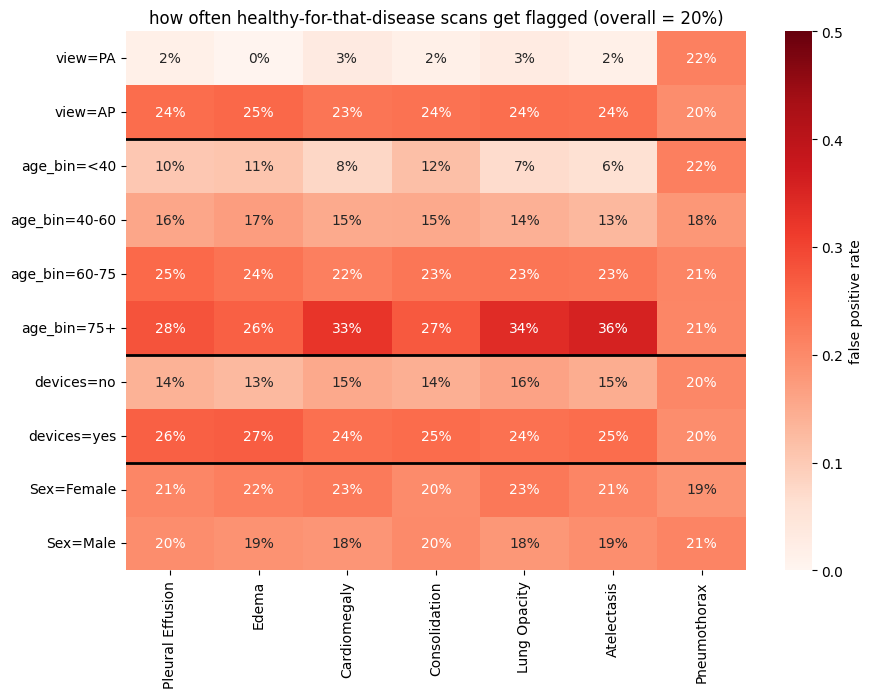

In [11]:
"""
Subgroup FPR rate map, shows which subgroup get more or less false positive than the average, shown per diagnosis
"""

import seaborn as sns
import matplotlib.pyplot as plt

row_order = ["view=PA", "view=AP",
             "age_bin=<40", "age_bin=40-60", "age_bin=60-75", "age_bin=75+",
             "devices=no", "devices=yes",
             "Sex=Female", "Sex=Male"]
col_order = ["Pleural Effusion", "Edema", "Cardiomegaly", "Consolidation",
             "Lung Opacity", "Atelectasis", "Pneumothorax"]

piv = (sg.assign(sub=sg.group + "=" + sg.value)
         .pivot(index="sub", columns="pathology", values="fpr")
         .reindex(index=[r for r in row_order if r in sg.assign(sub=sg.group + "=" + sg.value)["sub"].values],
                  columns=col_order))

plt.figure(figsize=(10, 7))
ax = sns.heatmap(piv, cmap="Reds", vmin=0, vmax=0.5, annot=True, fmt=".0%", cbar_kws={"label": "false positive rate"})
# lines between view / age / devices / sex blocks
for y in [2, 6, 8]:
    ax.axhline(y, color="black", lw=2)
plt.title("how often healthy-for-that-disease scans get flagged (overall = 20%)")
plt.ylabel(""); plt.xlabel("")
plt.show()

In [13]:
sg.groupby("pathology").apply(lambda d: (d.fpr - d.fpr_delta).iloc[0]).round(3)  # overall fpr per pathology, just a check to see if I did it correct

,0
pathology,
Atelectasis,0.2
Cardiomegaly,0.2
Consolidation,0.2
Edema,0.2
Lung Opacity,0.2
Pleural Effusion,0.2
Pneumothorax,0.2


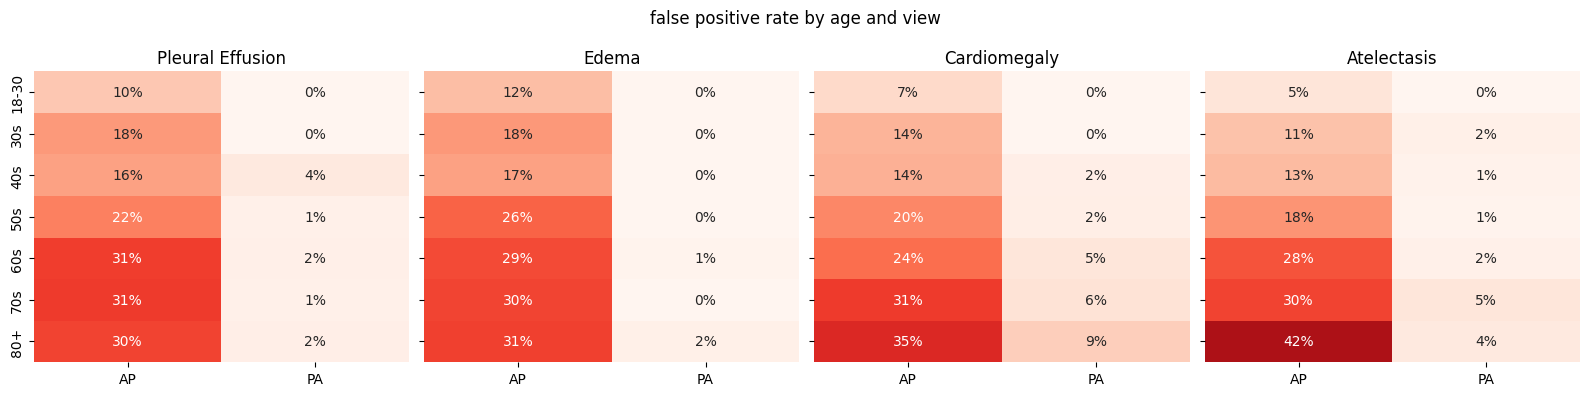

In [14]:
results["age10"] = pd.cut(results["Age"], bins=[17, 30, 40, 50, 60, 70, 80, 91],
                          labels=["18-30", "30s", "40s", "50s", "60s", "70s", "80+"])

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, c in zip(axes, ["Pleural Effusion", "Edema", "Cardiomegaly", "Atelectasis"]):
    pcol = "pred_" + name_map.get(c, c)
    d = results[(results[c] == 0) & results.view.isin(["AP", "PA"])].copy()
    d["fp"] = (d[pcol] > thr[c]).astype(int)
    tab = d.groupby(["age10", "view"], observed=True)["fp"].mean().unstack()
    sns.heatmap(tab, ax=ax, cmap="Reds", vmin=0, vmax=0.5, annot=True, fmt=".0%", cbar=False)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("false positive rate by age and view")
plt.tight_layout(); plt.show()

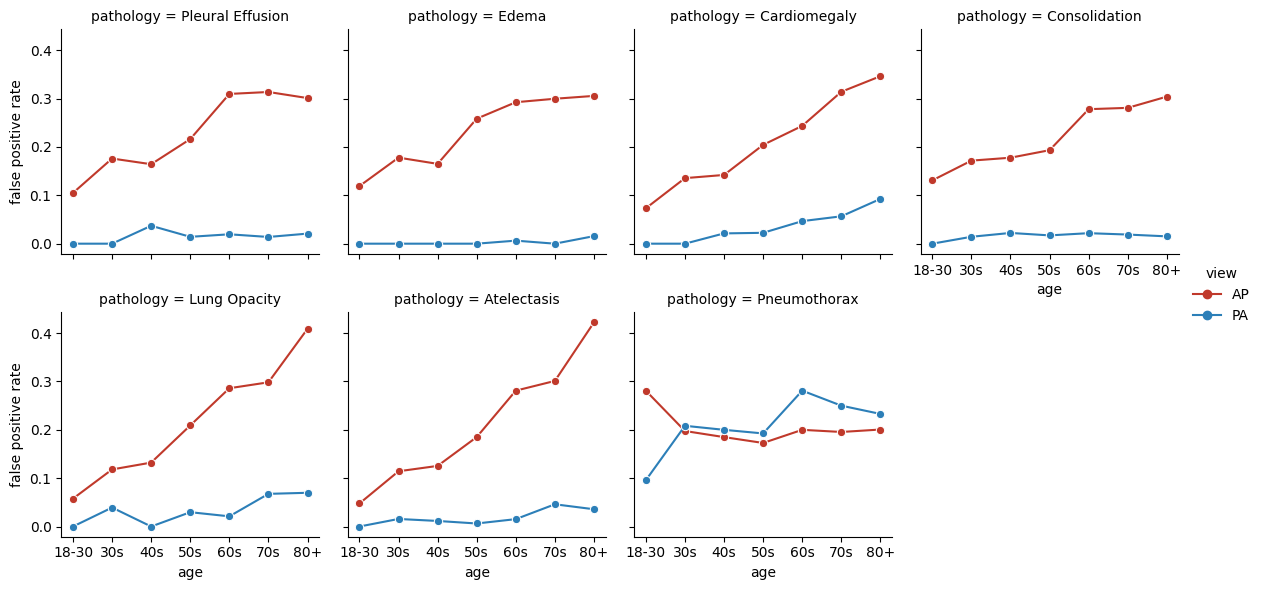

In [15]:
rows = []
for c in col_order:
    pcol = "pred_" + name_map.get(c, c)
    d = results[(results[c] == 0) & results.view.isin(["AP", "PA"])].copy()
    d["fp"] = (d[pcol] > thr[c]).astype(int)
    t = d.groupby(["age10", "view"], observed=True)["fp"].mean().reset_index()
    t["pathology"] = c
    rows.append(t)
lines = pd.concat(rows)

g = sns.relplot(data=lines, x="age10", y="fp", hue="view", col="pathology", col_wrap=4,
                kind="line", marker="o", height=3, palette={"AP": "#c0392b", "PA": "#2c7fb8"})
g.set_axis_labels("age", "false positive rate")
plt.show()

In [17]:
"""
### Separating view, age and devices
These three are tangled together, since older patients get more AP scans and have more tubes.
So we hold view fixed and look at age and devices within each view. Result for Pleural Effusion:
AP negatives get flagged 14 to 32% of the time, PA negatives 0 to 2%. Age and devices only make a difference within AP.
So almost everything runs through the AP view.
"""

# fpr on negatives, split by view and age at the same time
c, pcol = "Pleural Effusion", "pred_Effusion"
d = results[results[c] == 0].copy()
#tuned treshold again
d["fp"] = (d[pcol] > thr[c]).astype(int)

tab = d[d.view.isin(["AP", "PA"])].groupby(["view", "age_bin"], observed=True)["fp"].agg(["mean", "count"])
print(tab.unstack(0).round(3))

# same thing but view vs devices
tab2 = d[d.view.isin(["AP", "PA"]) & d.devices.isin(["yes", "no"])].groupby(["view", "devices"])["fp"].agg(["mean", "count"])
print(tab2.unstack(0).round(3))

          mean        count     
view        AP     PA    AP   PA
age_bin                         
<40      0.138  0.000   376  124
40-60    0.197  0.023   768  222
60-75    0.298  0.021   688  140
75+      0.323  0.012   517   83
          mean        count     
view        AP     PA    AP   PA
devices                         
no       0.191  0.014  1047  421
yes      0.289  0.021  1293  145


In [18]:
results[["pred_Effusion", "pred_Cardiomegaly", "pred_Atelectasis"]].describe().round(3)

,pred_Effusion,pred_Cardiomegaly,pred_Atelectasis
count,5202.000,5202.000,5202.000
mean,0.796,0.707,0.804
std,0.233,0.223,0.176
min,0.010,0.004,0.012
25%,0.686,0.590,0.749
50%,0.908,0.755,0.870
75%,0.958,0.878,0.920
max,0.996,0.998,0.994


valid (radiologist labels) {'Atelectasis': np.float64(0.808), 'Cardiomegaly': np.float64(0.809), 'Edema': np.float64(0.869), 'Pleural Effusion': np.float64(0.882), 'Pneumothorax': np.float64(0.64)}
train (report labels) {'Atelectasis': np.float64(0.589), 'Cardiomegaly': np.float64(0.765), 'Edema': np.float64(0.764), 'Pleural Effusion': np.float64(0.817), 'Pneumothorax': np.float64(0.725)}
frontal only {'Atelectasis': np.float64(0.599), 'Cardiomegaly': np.float64(0.756), 'Edema': np.float64(0.769), 'Pleural Effusion': np.float64(0.82), 'Pneumothorax': np.float64(0.724)}
lateral only {'Atelectasis': None, 'Cardiomegaly': None, 'Edema': None, 'Pleural Effusion': None, 'Pneumothorax': None}
torch.Size([1, 224, 224]) -1024.0 1023.9998168945312


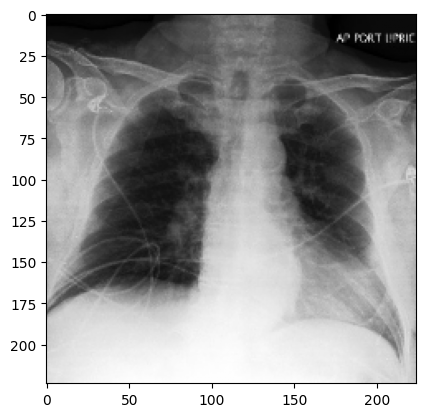

In [19]:
def auc_by(mask, label):
    out = {}
    for c in ["Atelectasis", "Cardiomegaly", "Edema", "Pleural Effusion", "Pneumothorax"]:
        m = mask & results[c].notna()
        y, p = results.loc[m, c], results.loc[m, "pred_" + name_map.get(c, c)]
        out[c] = round(roc_auc_score(y, p), 3) if y.nunique() == 2 else None
    print(label, out)

frontal = results.view != "Lateral"
auc_by(results.split == "valid", "valid (radiologist labels)")
auc_by(results.split == "train", "train (report labels)")
auc_by(frontal, "frontal only")
auc_by(~frontal, "lateral only")

# input range, should be about -1024 to 1024
x = XrayDS(sub["full_path"].tolist()[:1])[0]
print(x.shape, x.min().item(), x.max().item())

# eyeball one preprocessed image, should look like a normal chest xray
plt.imshow(x[0], cmap="gray"); plt.show()

In [20]:
"""
### Healthy patients only
AP patients are sicker, so a scan that's negative for one disease often has another one that looks similar.
That could explain the AP false alarms without any shortcut.
To rule this out we only keep fully healthy scans (No Finding = 1).
Result: the AP false positive rate drops from 19 to 32% to 4 to 7.5%,
so most of the effect was real overlapping disease.
But healthy AP scans still get flagged, while healthy PA scans never do (0 of 167).
"""
# only completely healthy scans, so no other disease can explain the false alarms
healthy = results[(results["No Finding"] == 1) & results.view.isin(["AP", "PA"])].copy()
for c in ["Pleural Effusion", "Edema", "Cardiomegaly", "Atelectasis"]:
    pcol = "pred_" + name_map.get(c, c)
    healthy["fp"] = (healthy[pcol] > thr[c]).astype(int)
    print(c, healthy.groupby("view")["fp"].agg(["mean", "count"]).round(3).to_dict())

Pleural Effusion {'mean': {'AP': 0.075, 'PA': 0.0}, 'count': {'AP': 320, 'PA': 167}}
Edema {'mean': {'AP': 0.059, 'PA': 0.0}, 'count': {'AP': 320, 'PA': 167}}
Cardiomegaly {'mean': {'AP': 0.062, 'PA': 0.0}, 'count': {'AP': 320, 'PA': 167}}
Atelectasis {'mean': {'AP': 0.044, 'PA': 0.0}, 'count': {'AP': 320, 'PA': 167}}


In [21]:
"""
Check that the healthy AP vs PA difference isn't chance.
Fisher's exact test on the false positive counts, plus a Mann-Whitney test on the raw scores,
which needs no threshold. On healthy patients AP scans get about 3x higher scores than PA
(Effusion median 0.59 vs 0.16), p between 1e-24 and 1e-45.
So something about AP images themselves pushes the model toward a diagnosis.
"""


from scipy.stats import fisher_exact, mannwhitneyu

for c in ["Pleural Effusion", "Edema", "Cardiomegaly", "Atelectasis"]:
    pcol = "pred_" + name_map.get(c, c)
    ap = healthy[healthy.view == "AP"]
    pa = healthy[healthy.view == "PA"]
    fp_ap, fp_pa = (ap[pcol] > thr[c]).sum(), (pa[pcol] > thr[c]).sum()
    _, p_fisher = fisher_exact([[fp_ap, len(ap) - fp_ap], [fp_pa, len(pa) - fp_pa]])
    # no threshold at all, just are ap scores higher than pa scores
    _, p_mw = mannwhitneyu(ap[pcol], pa[pcol], alternative="greater")
    print(c, "median AP", round(ap[pcol].median(), 3), "median PA", round(pa[pcol].median(), 3),
          "fisher p", f"{p_fisher:.1e}", "mw p", f"{p_mw:.1e}")

Pleural Effusion median AP 0.594 median PA 0.158 fisher p 6.7e-05 mw p 7.2e-39
Edema median AP 0.591 median PA 0.207 fisher p 3.5e-04 mw p 1.3e-45
Cardiomegaly median AP 0.547 median PA 0.168 fisher p 3.6e-04 mw p 3.0e-24
Atelectasis median AP 0.687 median PA 0.414 fisher p 3.3e-03 mw p 2.5e-42


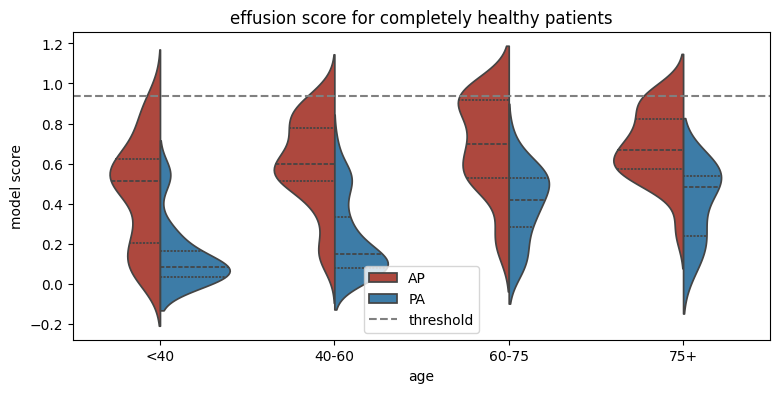

In [22]:
hp = healthy.copy()
hp["age10"] = pd.cut(hp["Age"], bins=[17, 40, 60, 75, 91], labels=["<40", "40-60", "60-75", "75+"])

plt.figure(figsize=(9, 4))
sns.violinplot(data=hp, x="age10", y="pred_Effusion", hue="view", split=True, inner="quartile",
               palette={"AP": "#c0392b", "PA": "#2c7fb8"})
plt.axhline(thr["Pleural Effusion"], ls="--", color="gray", label="threshold")
plt.title("effusion score for completely healthy patients")
plt.ylabel("model score"); plt.xlabel("age"); plt.legend()
plt.show()

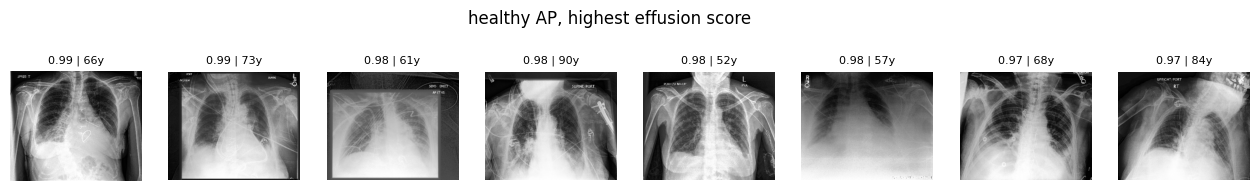

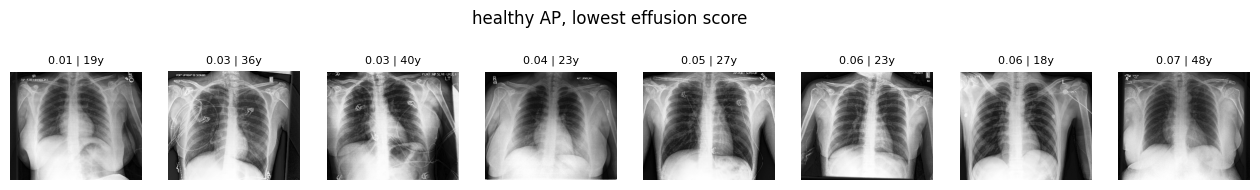

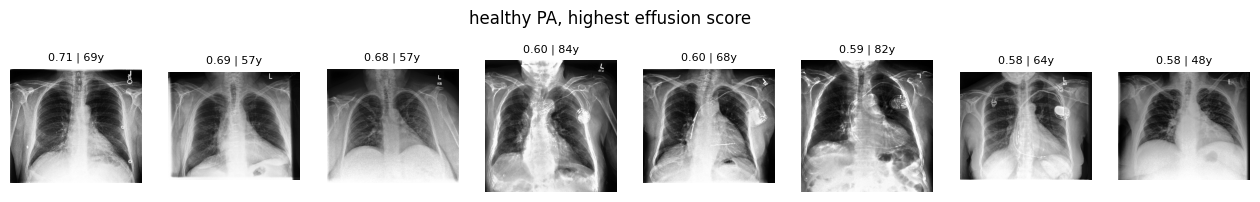

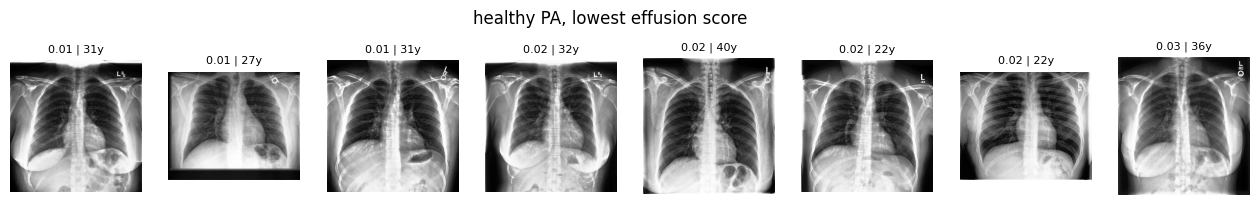

In [24]:
def show_grid(df, title, n=8):
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.4))
    for ax, (_, r) in zip(axes, df.head(n).iterrows()):
        ax.imshow(skimage.io.imread(r["full_path"]), cmap="gray")
        ax.set_title(f"{r['pred_Effusion']:.2f} | {int(r['Age'])}y", fontsize=8)
        ax.axis("off")
    plt.suptitle(title); plt.show()

hap = healthy[healthy.view == "AP"].sort_values("pred_Effusion", ascending=False)
show_grid(hap, "healthy AP, highest effusion score")
show_grid(hap.iloc[::-1], "healthy AP, lowest effusion score")
show_grid(healthy[healthy.view == "PA"].sort_values("pred_Effusion", ascending=False), "healthy PA, highest effusion score")
show_grid(healthy[healthy.view == "PA"].sort_values("pred_Effusion", ascending=True), "healthy PA, lowest effusion score")

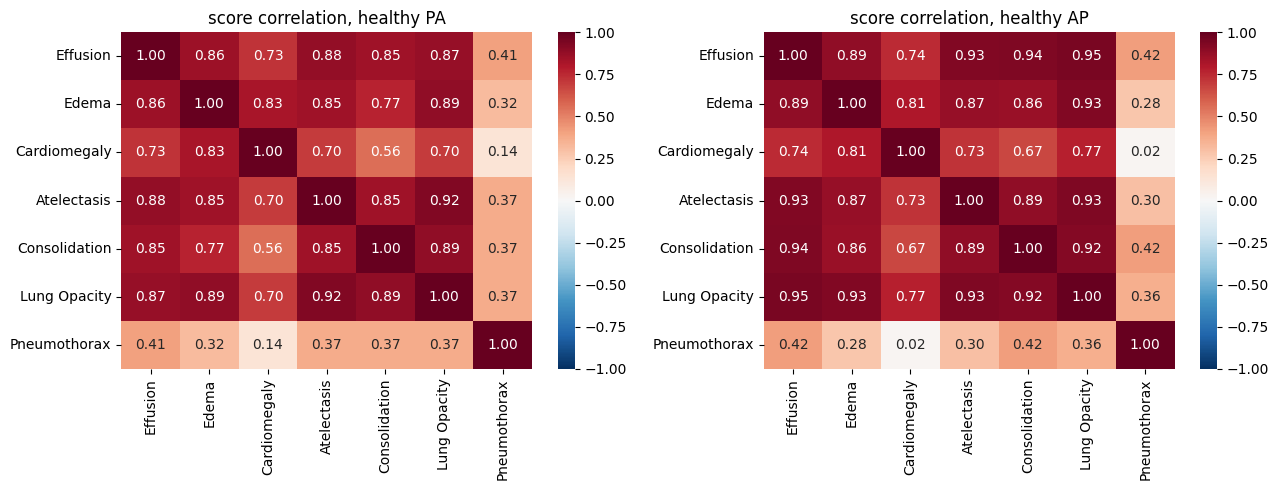

In [25]:
cols = ["pred_Effusion", "pred_Edema", "pred_Cardiomegaly", "pred_Atelectasis",
        "pred_Consolidation", "pred_Lung Opacity", "pred_Pneumothorax"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, v in zip(axes, ["PA", "AP"]):
    corr = healthy[healthy.view == v][cols].corr()
    sns.heatmap(corr, ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
                xticklabels=[c[5:] for c in cols], yticklabels=[c[5:] for c in cols])
    ax.set_title(f"score correlation, healthy {v}")
plt.tight_layout(); plt.show()

In [27]:
def mask_border(img, frac=0.075):
    # black out a band around the edges, that's where markers like "AP PORT" usually sit
    img = img.copy()
    h, w = img.shape[-2:]
    bh, bw = int(h * frac), int(w * frac)
    fill = img.min()
    img[..., :bh, :] = fill
    img[..., -bh:, :] = fill
    img[..., :, :bw] = fill
    img[..., :, -bw:] = fill
    return img

class XrayDSPert(XrayDS):
    def __init__(self, paths, perturb=None):
        super().__init__(paths)
        self.perturb = perturb
    def __getitem__(self, i):
        x = super().__getitem__(i).numpy()
        if self.perturb is not None:
            x = self.perturb(x)
        return torch.from_numpy(x).float()

def run_model(paths, perturb=None):
    loader = DataLoader(XrayDSPert(paths, perturb), batch_size=64, num_workers=2)
    outs = []
    with torch.no_grad():
        for x in loader:
            outs.append(model(x.to(device)).cpu().numpy())
    return pd.DataFrame(np.concatenate(outs), columns=["pred_" + p for p in model.pathologies])

# healthy ap and pa only, before vs after masking
h = healthy.reset_index(drop=True)
masked = run_model(h["full_path"].tolist(), mask_border)

for c in ["Pleural Effusion", "Edema", "Cardiomegaly", "Atelectasis"]:
    pcol = "pred_" + name_map.get(c, c)
    h[pcol + "_masked"] = masked[pcol].values
    for v in ["AP", "PA"]:
        dv = h[h.view == v]
        print(c, v,
              "median", round(dv[pcol].median(), 3), "->", round(dv[pcol + "_masked"].median(), 3),
              "| fp", round((dv[pcol] > thr[c]).mean(), 3), "->", round((dv[pcol + "_masked"] > thr[c]).mean(), 3))

Pleural Effusion AP median 0.594 -> 0.513 | fp 0.075 -> 0.019
Pleural Effusion PA median 0.158 -> 0.059 | fp 0.0 -> 0.0
Edema AP median 0.591 -> 0.549 | fp 0.059 -> 0.028
Edema PA median 0.207 -> 0.067 | fp 0.0 -> 0.0
Cardiomegaly AP median 0.547 -> 0.568 | fp 0.062 -> 0.084
Cardiomegaly PA median 0.168 -> 0.15 | fp 0.0 -> 0.018
Atelectasis AP median 0.687 -> 0.607 | fp 0.044 -> 0.012
Atelectasis PA median 0.414 -> 0.257 | fp 0.0 -> 0.0


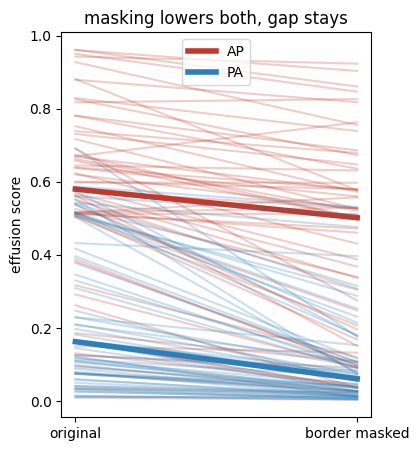

In [28]:
fig, ax = plt.subplots(figsize=(4, 5))
for v, col in [("AP", "#c0392b"), ("PA", "#2c7fb8")]:
    dv = h[h.view == v].sample(min(60, (h.view == v).sum()), random_state=0)
    for _, r in dv.iterrows():
        ax.plot([0, 1], [r["pred_Effusion"], r["pred_Effusion_masked"]], color=col, alpha=0.25)
    ax.plot([0, 1], [dv["pred_Effusion"].median(), dv["pred_Effusion_masked"].median()], color=col, lw=4, label=v)
ax.set_xticks([0, 1]); ax.set_xticklabels(["original", "border masked"])
ax.set_ylabel("effusion score"); ax.legend(); ax.set_title("masking lowers both, gap stays")
plt.show()

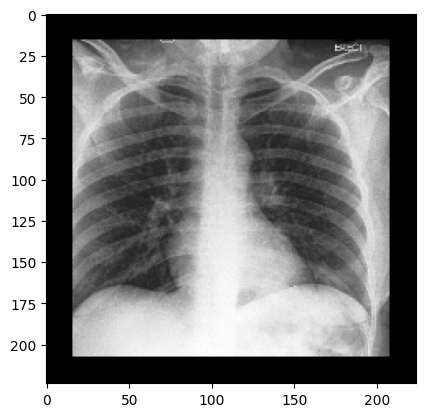

In [ ]:
x = XrayDSPert(h[h.view == "AP"]["full_path"].tolist()[:1], mask_border)[0]
plt.imshow(x[0], cmap="gray"); plt.show()